# 从图文 PDF 到 RAG 回答

从一份两页的图书借阅说明出发，依次查看 Docling 的解析块、RAGAnything 的多模态描述、LightRAG 保存的文本块和索引，以及一次提问的证据、提示词和回答。

按顺序运行单元。安装和启动命令见 [README](../README.md)。解析在本地进行。入库和提问会调用云端的文本、视觉和嵌入模型。

## 1. 配置文件、存储和云端模型

从项目根目录启动 JupyterLab，并加载 `src/.env`。内核会向上查找包含 `pyproject.toml` 的项目根目录，再定位 PDF 和产物目录。配置输出只显示路径和模型名称。

In [1]:
import os
from collections import Counter
from pathlib import Path

from IPython.display import Image, Markdown, display
from lightrag import QueryParam
from lightrag.llm.openai import openai_complete_if_cache, openai_embed
from lightrag.utils import EmbeddingFunc
from raganything import RAGAnything, RAGAnythingConfig

cwd = Path.cwd().resolve()
project_dir = next((path for path in (cwd, *cwd.parents) if (path / "pyproject.toml").is_file()), None)
if project_dir is None:
    raise FileNotFoundError("找不到项目根目录，请从项目根目录启动 JupyterLab。")

pdf_path = project_dir / "data/library-guide.pdf"
parsed_dir = project_dir / "outputs/parsed"
storage_dir = project_dir / "outputs/library_rag_storage"

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("OPENAI_BASE_URL")
llm_model = os.getenv("LLM_MODEL")
vision_model = os.getenv("VISION_MODEL")
embedding_model = os.getenv("EMBEDDING_MODEL")
embedding_dim = int(os.getenv("EMBEDDING_DIM"))

print(f"原始文件：{pdf_path.name}")
print(f"解析目录：{parsed_dir}")
print(f"索引目录：{storage_dir}")
print(f"文本：{llm_model}，视觉：{vision_model}，嵌入：{embedding_model}（{embedding_dim} 维）")

原始文件：library-guide.pdf
解析目录：/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/parsed
索引目录：/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage
文本：gpt-6-luna，视觉：gpt-6-luna，嵌入：text-embedding-3-small（1536 维）


## 2. 记录三种模型调用

三个异步函数把输入记到 `calls`，再调用 LightRAG 的 OpenAI 辅助函数，成功返回后补记输出。文本和视觉记录保留提示词。视觉消息中的图片记录类型和 URL 字符数，原始图片可以在解析单元查看。嵌入记录保留输入文本、输出形状和第一条向量的前六个数。

`EmbeddingFunc` 向 LightRAG 声明向量维度与输入长度。调用 `openai_embed.func` 可复用官方嵌入实现，同时把本教程配置的维度传给 API。

In [2]:
calls = []


async def llm(prompt, system_prompt=None, history_messages=None, **kwargs):
    call = {
        "kind": "llm",
        "model": llm_model,
        "prompt": prompt,
        "system_prompt": system_prompt,
        "history_messages": history_messages or [],
        "keyword_extraction": kwargs.get("keyword_extraction", False),
    }
    calls.append(call)
    output = await openai_complete_if_cache(
        llm_model, prompt, system_prompt=system_prompt,
        history_messages=history_messages, base_url=base_url, api_key=api_key, **kwargs,
    )
    call["output"] = output
    return output


async def vision(prompt, system_prompt=None, image_data=None, messages=None, **kwargs):
    # 图片入库传入 Docling PNG 的 base64，图片增强问答传入完整 messages。
    if messages is None:
        messages = []
        if system_prompt:
            messages.append({"role": "system", "content": system_prompt})
        content = prompt
        if image_data:
            content = [
                {"type": "text", "text": prompt},
                {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{image_data}"}},
            ]
        messages.append({"role": "user", "content": content})

    summary = []
    image_count = 0
    for message in messages:
        content = message["content"]
        if isinstance(content, list):
            parts = []
            for part in content:
                if part["type"] == "image_url":
                    parts.append({"type": "image_url", "url_chars": len(part["image_url"]["url"])})
                    image_count += 1
                else:
                    parts.append(part)
            content = parts
        summary.append({"role": message["role"], "content": content})

    call = {"kind": "vision", "model": vision_model, "messages": summary, "images": image_count}
    calls.append(call)
    output = await openai_complete_if_cache(
        vision_model, "", messages=messages, base_url=base_url, api_key=api_key, **kwargs,
    )
    call["output"] = output
    return output


async def embed(texts):
    call = {"kind": "embed", "model": embedding_model, "texts": list(texts)}
    calls.append(call)
    vectors = await openai_embed.func(
        texts, model=embedding_model, base_url=base_url, api_key=api_key,
        embedding_dim=embedding_dim, max_token_size=8192,
    )
    call["output"] = {"shape": vectors.shape, "first_vector_sample": vectors[0, :6].tolist()}
    return vectors

## 3. 创建 RAGAnything 并预览原始材料

打开 [原始 PDF](../data/library-guide.pdf) 对照阅读。第一页有学生借阅规则表，第二页有续借说明和操作图。

把 Docling、三个模型回调和存储位置交给 `RAGAnything`。这里设置较小的文本块长度，便于在这份短文档中观察切块。

In [3]:
from raganything import set_prompt_language

set_prompt_language("zh")

config = RAGAnythingConfig(
    parser="docling",
    parser_output_dir=str(parsed_dir),
    working_dir=str(storage_dir),
    display_content_stats=False,
)

rag = RAGAnything(
    config=config,
    llm_model_func=llm,
    vision_model_func=vision,
    embedding_func=EmbeddingFunc(
        embedding_dim=embedding_dim,
        max_token_size=8192,
        model_name=embedding_model,
        func=embed,
    ),
    lightrag_kwargs={
        "llm_model_name": llm_model,
        "chunk_token_size": 75,
        "chunk_overlap_token_size": 20,
        "addon_params": {"language": "Chinese"},
    },
)

INFO: Created working directory: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage
INFO: RAGAnything initialized with config:
INFO:   Working directory: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage
INFO:   Parser: docling
INFO:   Parse method: auto
INFO:   Multimodal processing - Image: True, Table: True, Equation: True
INFO:   Max concurrent files: 1


## 4. 解析 PDF

`await rag.parse_document(...)` 返回 `content_list` 和内容对应的 `doc_id`。列表中每个字典包含块类型和从 0 起算的页号。下面打印实际块，图片块另外以内嵌图片显示。Docling 的表格可能包含单元格结构。这份示例没有公式，如果换用带公式的 PDF，识别出的 `equation` 块也会出现在列表里。

示例 PDF 已有文字层，这里关闭 OCR。首次运行时 Docling 可能下载本地解析所需的模型文件。

INFO: Starting document parsing: /Users/weiningxu/Documents/Project/rag_anything_playground/data/library-guide.pdf
INFO: Using docling parser with method: auto
INFO: Detected PDF file, using parser for PDF...
/Users/weiningxu/Documents/Project/rag_anything_playground/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1113 17:55:28.174000 62012 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 770/770 [00:00<00:00, 12267.59it/s]
INFO: Parsing /Users/weiningxu/Documents/Project/rag_anything_playground/data/library-guide.pdf complete! Extracted 23 content blocks


doc_id = doc-aa78aa4bc3e5b28e98e8d9f587736a42


{'text': 21, 'table': 1, 'image': 1}

{'type': 'text', 'text': '图书借阅规则', 'page_idx': 0}

{'type': 'text', 'text': '学生借书和还书', 'page_idx': 0}

{'type': 'text', 'text': '借书时，先确认账户可以借阅。', 'page_idx': 0}

... (10 outputs left out)

{'type': 'text', 'text': '打开借阅页面，找到这本书，点击"续借"。', 'page_idx': 1}

{'type': 'text', 'text': '如果没有人预约这本书，可以续借一次，延长 7 天。', 'page_idx': 1}

{'type': 'text', 'text': '有人预约时，请按原到期日归还。', 'page_idx': 1}

{'type': 'image',
 'img_path': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/parsed/library-guide_39d2f00c/library-guide/docling/images/image_0.png',
 'image_caption': [],
 'image_footnote': [],
 'page_idx': 1}

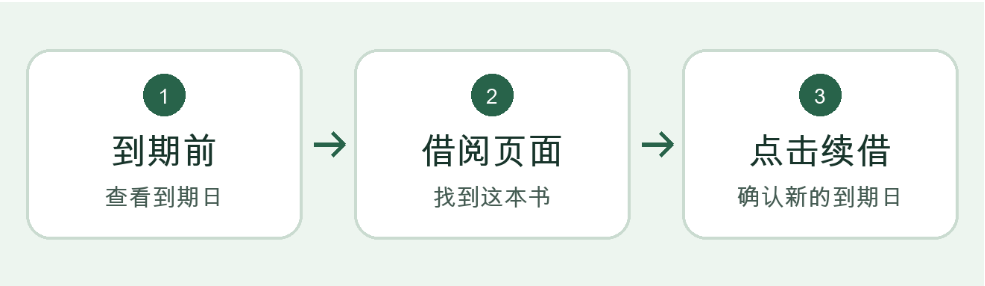

{'type': 'text', 'text': '图 1 续借步骤', 'page_idx': 1}

{'type': 'text', 'text': '确认结果', 'page_idx': 1}

{'type': 'text', 'text': '续借成功后，借阅页面会显示新的到期日。', 'page_idx': 1}

{'type': 'text', 'text': '归还前，再确认一次页面上的日期。', 'page_idx': 1}

{'type': 'text', 'text': '图书借阅指南', 'page_idx': 1}

{'type': 'text', 'text': '2 / 2', 'page_idx': 1}

In [4]:
content_list, doc_id = await rag.parse_document(str(pdf_path), allow_ocr=False)

print(f"doc_id = {doc_id}")
display(dict(Counter(block["type"] for block in content_list)))

for block in content_list:
    display(block)
    if block["type"] == "image":
        display(Image(filename=block["img_path"], width=520))

## 5. 入库并查看多模态描述

将刚得到的块和 `doc_id` 交给 `insert_content_list`。官方流程切分正文，生成图片和表格描述，抽取实体和关系，并写入文本块、向量和图谱。表格描述走文本回调，图片描述走视觉回调。

`insert_content_list` 成功时返回 `None`。用 `get_document_processing_status` 查看文档是否处理完成，再从本次入库新增的调用记录里查看描述和嵌入样例。

In [5]:
if not api_key:
    raise RuntimeError("请在 src/.env 中设置 OPENAI_API_KEY，再从项目根目录运行 uv run --env-file src/.env jupyter lab。")

before_insert = len(calls)
await rag.insert_content_list(content_list, file_path=str(pdf_path), doc_id=doc_id)
status = await rag.get_document_processing_status(doc_id)
display(status)

if not status["fully_processed"]:
    raise RuntimeError("文档入库未完成，请查看上面的文档状态和库日志。")

INFO: Parser 'docling' installation verified
INFO: Initializing LightRAG with parameters: {'working_dir': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage', 'llm_model_name': 'gpt-6-luna', 'chunk_token_size': 75, 'chunk_overlap_token_size': 20, 'addon_params': {'language': 'Chinese'}}
INFO: [] Created new empty graph file: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage/graph_chunk_entity_relation.graphml
INFO:nano-vectordb:Init {'embedding_dim': 1536, 'metric': 'cosine', 'storage_file': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage/vdb_entities.json'} 0 data
INFO:nano-vectordb:Init {'embedding_dim': 1536, 'metric': 'cosine', 'storage_file': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage/vdb_relationships.json'} 0 data
INFO:nano-vectordb:Init {'embedding_dim': 1536, 'metric': 'cosine', 'storage_file': '/Users/weiningxu/Document

{'exists': True,
 'text_processed': True,
 'multimodal_processed': True,
 'fully_processed': True,
 'chunks_count': 6,
 'chunks_list': ['chunk-b2e2b287c866ec278f10c12fc3923d08',
  'chunk-951e510f42b703ea5ab244c339c57fd8',
  'chunk-8b3b4a368a464a5c56faf12fd0fc8008',
  'chunk-4cd91488171d5211f450daaa06e8e4a5',
  'chunk-343d7fa6d9bf6c548bdd0b502c7c11af',
  'chunk-404daa6b949e1384db69a1327869caf0'],
 'status': <DocStatus.PROCESSED: 'processed'>,
 'updated_at': '2026-11-13T09:57:25+00:00',
 'raw_status': {'status': <DocStatus.PROCESSED: 'processed'>,
  'chunks_count': 6,
  'chunks_list': ['chunk-b2e2b287c866ec278f10c12fc3923d08',
   'chunk-951e510f42b703ea5ab244c339c57fd8',
   'chunk-8b3b4a368a464a5c56faf12fd0fc8008',
   'chunk-4cd91488171d5211f450daaa06e8e4a5',
   'chunk-343d7fa6d9bf6c548bdd0b502c7c11af',
   'chunk-404daa6b949e1384db69a1327869caf0'],
  'content_summary': '图书借阅规则\n\n学生借书和还书\n\n借书时，先确认账户可以借阅。\n\n每次可借的数量和借阅期限见下表。\n\n查看到期日\n\n借阅成功后，借阅页面会显示每本书的到期日。\n\n如果借了几本书，可以按书名分别查看。\n\n请在到期

INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


In [6]:
from raganything.prompt import PROMPTS

index_calls = calls[before_insert:]
display(dict(Counter(call["kind"] for call in index_calls)))

description_prompts = {PROMPTS["TABLE_ANALYSIS_SYSTEM"], PROMPTS["EQUATION_ANALYSIS_SYSTEM"]}
for call in index_calls:
    if call["kind"] == "vision" or call.get("system_prompt") in description_prompts:
        display(call)

embedding_sample = next((call for call in index_calls if call["kind"] == "embed"), None)
if embedding_sample:
    display(embedding_sample)

{'embed': 137, 'llm': 13, 'vision': 1}

{'kind': 'llm',
 'model': 'gpt-6-luna',
 'prompt': '请结合上下文分析此表格内容，并以以下JSON结构提供回答：\n\n{\n    "detailed_description": "对表格的全面分析，包括：\n    - 表格结构和组织方式\n    - 列标题及其含义\n    - 关键数据点和模式\n    - 统计洞察和趋势\n    - 数据元素之间的关系\n    - 所呈现数据与周围上下文的重要性\n    - 表格如何支持或说明周围内容中的概念\n    始终使用具体名称和数值而非笼统引用。",\n    "entity_info": {\n        "entity_name": "descriptive name for this table",\n        "entity_type": "table",\n        "summary": "表格目的、关键发现及与周围内容关系的简明摘要（不超过100字）"\n    }\n}\n\n周围内容上下文：\n图书借阅规则\n学生借书和还书\n借书时，先确认账户可以借阅。\n每次可借的数量和借阅期限见下表。\n查看到期日\n借阅成功后，借阅页面会显示每本书的到期日。\n如果借了几本书，可以按书名分别查看。\n请在到期日当天或之前归还图书。\n图书借阅指南\n1 / 2\n[Page 1] 怎么续借\n[Page 1] 还没读完时，可以在到期前申请续借。\n[Page 1] 打开借阅页面，找到这本书，点击"续借"。\n[Page 1] 如果没有人预约这本书，可以续借一次，延长 7 天。\n[Page 1] 有人预约时，请按原到期日归还。\n[Page 1] 图 1 续借步骤\n[Page 1] 确认结果\n[Page 1] 续借成功后，借阅页面会显示新的到期日。\n[Page 1] 归还前，再确认一次页面上的日期。\n[Page 1] 图书借阅指南\n[Page 1] 2 / 2\n\n表格信息：\n图片路径：\n标题：None\n内容：{\'table_cells\': [{\'bbox\': {\'l\': 75.0, \'t\': 272.5795905, \'r\': 105.0, \'b\': 286.6494135, \'coor

{'kind': 'vision',
 'model': 'gpt-6-luna',
 'messages': [{'role': 'system', 'content': '你是一位专业的图像分析专家。请提供详细、准确的描述。'},
  {'role': 'user',
   'content': [{'type': 'text',
     'text': '请结合上下文详细分析这张图片，并以以下JSON结构提供回答：\n\n{\n    "detailed_description": "对图片的全面详细描述，遵循以下指导：\n    - 描述整体构图和布局\n    - 识别所有对象、人物、文字和视觉元素\n    - 解释元素之间的关系及其与上下文的联系\n    - 注意颜色、光照和视觉风格\n    - 描述展示的任何动作或活动\n    - 如涉及图表、图解等，包含技术细节\n    - 在相关时引用与周围内容的联系\n    - 始终使用具体名称而非代词",\n    "entity_info": {\n        "entity_name": "unique descriptive name for this image",\n        "entity_type": "image",\n        "summary": "图片内容、重要性及与周围内容关系的简明摘要（不超过100字）"\n    }\n}\n\n周围内容上下文：\n[Page 0] 图书借阅规则\n[Page 0] 学生借书和还书\n[Page 0] 借书时，先确认账户可以借阅。\n[Page 0] 每次可借的数量和借阅期限见下表。\n[Page 0] 查看到期日\n[Page 0] 借阅成功后，借阅页面会显示每本书的到期日。\n[Page 0] 如果借了几本书，可以按书名分别查看。\n[Page 0] 请在到期日当天或之前归还图书。\n[Page 0] 图书借阅指南\n[Page 0] 1 / 2\n怎么续借\n还没读完时，可以在到期前申请续借。\n打开借阅页面，找到这本书，点击"续借"。\n如果没有人预约这本书，可以续借一次，延长 7 天。\n有人预约时，请按原到期日归还。\n图 1 续借步骤\n确认结果\n续借成功后，借阅页面会显示新的到期日。\n归还前，再确认一

{'kind': 'embed',
 'model': 'text-embedding-3-small',
 'texts': ['图书借阅规则\n\n学生借书和还书\n\n借书时，先确认账户可以借阅。\n\n每次可借的数量和借阅期限见下表。\n\n查看到期日\n\n借阅成功后，借阅页面会显示每本书的到期日。\n\n如果借了几本书，可以按书名分别查看。\n\n请',
  '书的到期日。\n\n如果借了几本书，可以按书名分别查看。\n\n请在到期日当天或之前归还图书。\n\n图书借阅指南\n\n1 / 2\n\n怎么续借\n\n还没读完时，可以在到期前申请续借。\n\n打开借阅页面，找到这本书，点击"续借',
  '期前申请续借。\n\n打开借阅页面，找到这本书，点击"续借"。\n\n如果没有人预约这本书，可以续借一次，延长 7 天。\n\n有人预约时，请按原到期日归还。\n\n图 1 续借步骤\n\n确认结果\n\n续借成功后，借阅页面会显示新的到',
  '续借步骤\n\n确认结果\n\n续借成功后，借阅页面会显示新的到期日。\n\n归还前，再确认一次页面上的日期。\n\n图书借阅指南\n\n2 / 2'],
 'output': {'shape': (4, 1536),
  'first_vector_sample': [0.015777587890625,
   0.046966552734375,
   0.00588226318359375,
   -0.0224761962890625,
   0.005893707275390625,
   0.0060882568359375]}}

## 6. 读取文本块、向量和知识图谱

从文档状态取出 `chunks_list`。用同一个块 ID 在 `text_chunks` 读取正文和元数据，再在 `chunks_vdb` 找对应的向量。只打印维度和前六个数。默认向量存储用 float16 压缩，读回的数值可能与模型回调的原始值略有差别。

`get_knowledge_graph("*", max_nodes=30)` 读取最多 30 个节点及其相关边。可对照节点和边属性里的 `source_id` 与上面的块 ID。

In [7]:
chunk_ids = status["chunks_list"]
chunks = await rag.lightrag.text_chunks.get_by_ids(chunk_ids)

for chunk_id, chunk in zip(chunk_ids, chunks):
    print(f"块 ID：{chunk_id}")
    if chunk is not None:
        display({key: value for key, value in chunk.items() if key != "content"})
        print(chunk["content"], end="\n\n")

vectors_by_id = await rag.lightrag.chunks_vdb.get_vectors_by_ids(chunk_ids[:3])
display({
    chunk_id: {"dimensions": len(vector), "sample": vector[:6]}
    for chunk_id, vector in vectors_by_id.items()
})

块 ID：chunk-b2e2b287c866ec278f10c12fc3923d08


{'tokens': 75,
 'chunk_order_index': 0,
 'full_doc_id': 'doc-aa78aa4bc3e5b28e98e8d9f587736a42',
 'file_path': 'library-guide.pdf',
 'llm_cache_list': ['default:extract:804a50ec23b6645f877a0199d9562a39',
  'default:extract:9445eb46cb1e94fd7cd22d5caf218820'],
 'create_time': 1794563730,
 'update_time': 1794563771,
 '_id': 'chunk-b2e2b287c866ec278f10c12fc3923d08',
 'page_idx': 0}

图书借阅规则

学生借书和还书

借书时，先确认账户可以借阅。

每次可借的数量和借阅期限见下表。

查看到期日

借阅成功后，借阅页面会显示每本书的到期日。

如果借了几本书，可以按书名分别查看。

请

块 ID：chunk-951e510f42b703ea5ab244c339c57fd8


{'tokens': 75,
 'chunk_order_index': 1,
 'full_doc_id': 'doc-aa78aa4bc3e5b28e98e8d9f587736a42',
 'file_path': 'library-guide.pdf',
 'llm_cache_list': ['default:extract:8a2ea3018fe01ebe0e9feebebd3ea2a1',
  'default:extract:5420a23ace9d832bae85588565035df6'],
 'create_time': 1794563730,
 'update_time': 1794563771,
 '_id': 'chunk-951e510f42b703ea5ab244c339c57fd8',
 'page_idx': 0,
 'page_idx_end': 1}

书的到期日。

如果借了几本书，可以按书名分别查看。

请在到期日当天或之前归还图书。

图书借阅指南

1 / 2

怎么续借

还没读完时，可以在到期前申请续借。

打开借阅页面，找到这本书，点击"续借

块 ID：chunk-8b3b4a368a464a5c56faf12fd0fc8008


{'tokens': 75,
 'chunk_order_index': 2,
 'full_doc_id': 'doc-aa78aa4bc3e5b28e98e8d9f587736a42',
 'file_path': 'library-guide.pdf',
 'llm_cache_list': ['default:extract:31671700bf4063ebe5c5b1323beb7ac1',
  'default:extract:2aae3a6a9cdfb71852bc325cbece77cf'],
 'create_time': 1794563730,
 'update_time': 1794563771,
 '_id': 'chunk-8b3b4a368a464a5c56faf12fd0fc8008',
 'page_idx': 1}

... (4 outputs left out)

表格分析：
图片路径：
标题：None
结构：{'table_cells': [{'bbox': {'l': 75.0, 't': 272.5795905, 'r': 105.0, 'b': 286.6494135, 'coord_origin': 'TOPLEFT'}, 'row_span': 1, 'col_span': 1, 'start_row_offset_idx': 0, 'end_row_offset_idx': 1, 'start_col_offset_idx': 0, 'end_col_offset_idx': 1, 'text': '项目', 'column_header': True, 'row_header': False, 'row_section': False, 'fillable': False}, {'bbox': {'l': 321.0, 't': 272.5795905, 'r': 411.0, 'b': 286.6494135, 'coord_origin': 'TOPLEFT'}, 'row_span': 1, 'col_span': 1, 'start_row_offset_idx': 0, 'end_row_offset_idx': 1, 'start_col_offset_idx': 1, 'end_col_offset_idx': 2, 'text': '学生借阅规则', 'column_header': True, 'row_header': False, 'row_section': False, 'fillable': False}, {'bbox': {'l': 75.0, 't': 313.5795905, 'r': 180.0, 'b': 327.6494135, 'coord_origin': 'TOPLEFT'}, 'row_span': 1, 'col_span': 1, 'start_row_offset_idx': 1, 'end_row_offset_idx': 2, 'start_col_offset_idx': 0, 'end_col_offset_idx': 1, 'text': '每次最多借几本', 'column_header': False, 'row_header': False

{'tokens': 424,
 'full_doc_id': 'doc-aa78aa4bc3e5b28e98e8d9f587736a42',
 'chunk_order_index': 5,
 'file_path': 'library-guide.pdf',
 'llm_cache_list': ['default:extract:0e31ffbe5720f357555f225f2ac19141',
  'default:extract:502793b1161900a410863ea046d1ce66'],
 'is_multimodal': True,
 'modal_entity_name': '图书到期前续借三步流程 (image)',
 'original_type': 'image',
 'page_idx': 1,
 'create_time': 1794563779,
 'update_time': 1794563806,
 '_id': 'chunk-404daa6b949e1384db69a1327869caf0'}


图片内容分析：
- 章节路径：None
- 邻近文本：打开借阅页面，找到这本书，点击"续借"。 如果没有人预约这本书，可以续借一次，延长 7 天。 有人预约时，请按原到期日归还。 图 1 续借步骤 确认结果 续借成功后，借阅页面会显示新的到期日。
图片路径：/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/parsed/library-guide_39d2f00c/library-guide/docling/images/image_0.png
标注：None
脚注：None

视觉分析：图片是一张横向排列的三步图书续借流程信息图，背景为浅绿色。画面中有三个大小相近的白色圆角矩形卡片，卡片边缘带浅灰绿色描边；卡片之间以深绿色向右箭头连接，表示按顺序完成续借操作。每张卡片上方都有一个深绿色圆形编号标记，白色数字依次为“1”“2”“3”。第一张卡片写着“到期前”，下方说明“查看到期日”；第二张卡片写着“借阅页面”，下方说明“找到这本书”；第三张卡片写着“点击续借”，下方说明“确认新的到期日”。文字为深绿色或灰绿色，采用简洁清晰的无衬线风格，卡片内容居中排列，整体留白充足、视觉风格简洁柔和。该图与《图书借阅指南》的续借说明相对应：读者应在图书到期前打开借阅页面，找到要续借的书并点击“续借”，随后确认页面显示的新到期日。图中呈现的是操作步骤示意，不包含人物、实物书籍或具体界面截图。



{'chunk-b2e2b287c866ec278f10c12fc3923d08': {'dimensions': 1536,
  'sample': [0.015777587890625,
   0.046966552734375,
   0.00588226318359375,
   -0.0224761962890625,
   0.005893707275390625,
   0.0060882568359375]},
 'chunk-951e510f42b703ea5ab244c339c57fd8': {'dimensions': 1536,
  'sample': [0.0231781005859375,
   0.057891845703125,
   0.007137298583984375,
   -0.0289459228515625,
   -0.0125579833984375,
   -0.0012416839599609375]},
 'chunk-8b3b4a368a464a5c56faf12fd0fc8008': {'dimensions': 1536,
  'sample': [0.0085601806640625,
   0.061798095703125,
   0.005474090576171875,
   -0.016326904296875,
   -0.0173492431640625,
   -0.01788330078125]}}

In [8]:
graph = await rag.lightrag.get_knowledge_graph("*", max_nodes=30)
print(f"节点：{len(graph.nodes)}，边：{len(graph.edges)}，已截断：{graph.is_truncated}")
display(graph.model_dump())

INFO: [] Graph truncated: 45 nodes found, limited to 30
INFO: [] Subgraph query successful | Node count: 30 | Edge count: 67


节点：30，边：67，已截断：True


{'nodes': [{'id': '续借',
   'labels': ['续借'],
   'properties': {'entity_id': '续借',
    'entity_type': 'method',
    'description': '续借是在图书尚未读完时，于到期前申请延长借阅。<SEP>续借是通过借阅页面操作、在符合条件时延长图书借阅期限的操作。',
    'source_id': 'chunk-8b3b4a368a464a5c56faf12fd0fc8008<SEP>chunk-951e510f42b703ea5ab244c339c57fd8',
    'file_path': 'library-guide.pdf',
    'created_at': 1794563752,
    'truncate': ''}},
  {'id': '借阅页面',
   'labels': ['借阅页面'],
   'properties': {'entity_id': '借阅页面',
    'entity_type': 'artifact',
    'description': '借阅页面用于显示续借成功后的新到期日。<SEP>借阅页面用于找到图书并点击续借操作。<SEP>借阅页面用于查找图书、点击续借，并在续借成功后显示新的到期日。<SEP>借阅页面会显示每本已借图书的到期日，并支持按书名分别查看。<SEP>借阅页面用于查找待续借图书、发起续借，并显示续借后的新到期日。<SEP>借阅页面显示每本图书的到期日，续借后显示新的到期日。',
    'source_id': 'chunk-8b3b4a368a464a5c56faf12fd0fc8008<SEP>chunk-951e510f42b703ea5ab244c339c57fd8<SEP>chunk-b2e2b287c866ec278f10c12fc3923d08<SEP>chunk-4cd91488171d5211f450daaa06e8e4a5<SEP>chunk-343d7fa6d9bf6c548bdd0b502c7c11af<SEP>chunk-404daa6b949e1384db69a1327869caf0',
    'file_path': 'library-guid

## 7. 查看一次提问的检索证据

`rag.lightrag.aquery_data` 返回结构化结果。这里使用 `mix`，同时检索知识图谱和向量文本块，并关闭重排。下面查看检索关键词、实体、关系、证据块和来源。可通过 `reference_id` 将证据与来源文件对应起来。

这一步省去了最终答案生成。关键词抽取和向量检索仍可能调用云端模型。

In [9]:
question = "学生每次最多能借几本书、能借多久、怎么续借？"
print(question)

retrieval = await rag.lightrag.aquery_data(
    question, QueryParam(mode="mix", enable_rerank=False)
)

print(retrieval["status"], retrieval["message"])
print("关键词")
display(retrieval.get("metadata", {}).get("keywords", {}))

for field in ("entities", "relationships", "chunks", "references"):
    print(field)
    display(retrieval["data"].get(field, []))

学生每次最多能借几本书、能借多久、怎么续借？


INFO:  == LLM cache == saving: mix:keywords:786d4ccf980152c56d4c074af7e457dd
INFO: Query nodes: 学生, 每次最多借阅册数, 借阅时长, 续借方式 (top_k:40, cosine:0.2)
INFO: Local query: 40 entites, 85 relations
INFO: Query edges: 学生图书借阅规则, 图书借阅期限, 图书续借 (top_k:40, cosine:0.2)
INFO: Global query: 30 entites, 40 relations
INFO: Naive query: 6 chunks (chunk_top_k:20 cosine:0.2)
INFO: Raw search results: 41 entities, 85 relations, 6 vector chunks
INFO: After truncation: 41 entities, 85 relations
INFO: Selecting 6 from 6 entity-related chunks by vector similarity
INFO: Find no additional relations-related chunks from 85 relations
INFO: Round-robin merged chunks: 12 -> 6 (deduplicated 6)
INFO: Final context: 41 entities, 85 relations, 6 chunks
INFO: Final chunks S+F/O: E12/1 E15/2 E7/3 E6/4 E5/5 E12/6


success Query processed successfully
关键词


{'high_level': ['学生图书借阅规则', '图书借阅期限', '图书续借'],
 'low_level': ['学生', '每次最多借阅册数', '借阅时长', '续借方式']}

entities


[{'entity_name': '每次最多借3本',
  'entity_type': 'data',
  'description': '每次最多借3本是学生借阅图书的数量上限。',
  'source_id': 'chunk-343d7fa6d9bf6c548bdd0b502c7c11af',
  'file_path': 'library-guide.pdf',
  'created_at': 1794563806},
 {'entity_name': '可借数量和借阅期限',
  'entity_type': 'data',
  'description': '可借数量和借阅期限列于规则所指的表格中。',
  'source_id': 'chunk-b2e2b287c866ec278f10c12fc3923d08',
  'file_path': 'library-guide.pdf',
  'created_at': 1794563754},
 {'entity_name': '学生借阅规则',
  'entity_type': 'concept',
  'description': '学生借阅规则规定学生每次可借图书的数量上限和原始借阅期限。',
  'source_id': 'chunk-343d7fa6d9bf6c548bdd0b502c7c11af',
  'file_path': 'library-guide.pdf',
  'created_at': 1794563806},
 {'entity_name': '图书借阅规则',
  'entity_type': 'content',
  'description': '图书借阅规则说明学生借书、还书以及查看到期日的相关流程。',
  'source_id': 'chunk-b2e2b287c866ec278f10c12fc3923d08',
  'file_path': 'library-guide.pdf',
  'created_at': 1794563754},
 {'entity_name': '学生图书借阅数量与期限规则表 (table)',
  'entity_type': 'table',
  'description': '表格规定学生每次最多借3本、标准借阅期为14天；结合

... (2 outputs left out)

chunks


[{'reference_id': '1',
  'content': '图书借阅规则\n\n学生借书和还书\n\n借书时，先确认账户可以借阅。\n\n每次可借的数量和借阅期限见下表。\n\n查看到期日\n\n借阅成功后，借阅页面会显示每本书的到期日。\n\n如果借了几本书，可以按书名分别查看。\n\n请',
  'file_path': 'library-guide.pdf',
  'chunk_id': 'chunk-b2e2b287c866ec278f10c12fc3923d08'},
 {'reference_id': '1',
  'content': "表格分析：\n图片路径：\n标题：None\n结构：{'table_cells': [{'bbox': {'l': 75.0, 't': 272.5795905, 'r': 105.0, 'b': 286.6494135, 'coord_origin': 'TOPLEFT'}, 'row_span': 1, 'col_span': 1, 'start_row_offset_idx': 0, 'end_row_offset_idx': 1, 'start_col_offset_idx': 0, 'end_col_offset_idx': 1, 'text': '项目', 'column_header': True, 'row_header': False, 'row_section': False, 'fillable': False}, {'bbox': {'l': 321.0, 't': 272.5795905, 'r': 411.0, 'b': 286.6494135, 'coord_origin': 'TOPLEFT'}, 'row_span': 1, 'col_span': 1, 'start_row_offset_idx': 0, 'end_row_offset_idx': 1, 'start_col_offset_idx': 1, 'end_col_offset_idx': 2, 'text': '学生借阅规则', 'column_header': True, 'row_header': False, 'row_section': False, 'fillable': False}, {'bb

references


[{'reference_id': '1', 'file_path': 'library-guide.pdf'}]

## 8. 查看上下文和提示词

`only_need_context=True` 返回拼装后的证据文本。`only_need_prompt=True` 返回包含系统提示词和用户问题的预览。它们各自重新执行检索，和上一节的结构化证据一样，直接从索引取数据。

In [10]:
context = await rag.aquery(
    question, mode="mix", only_need_context=True, vlm_enhanced=False, enable_rerank=False,
)
print(context)

INFO: Executing text query: 学生每次最多能借几本书、能借多久、怎么续借？...
INFO: Query mode: mix
INFO: Query nodes: 学生, 每次最多借阅册数, 借阅时长, 续借方式 (top_k:40, cosine:0.2)
INFO: Local query: 40 entites, 85 relations
INFO: Query edges: 学生图书借阅规则, 图书借阅期限, 图书续借 (top_k:40, cosine:0.2)
INFO: Global query: 30 entites, 40 relations
INFO: Naive query: 6 chunks (chunk_top_k:20 cosine:0.2)
INFO: Raw search results: 41 entities, 85 relations, 6 vector chunks
INFO: After truncation: 41 entities, 85 relations
INFO: Selecting 6 from 6 entity-related chunks by vector similarity
INFO: Find no additional relations-related chunks from 85 relations
INFO: Round-robin merged chunks: 12 -> 6 (deduplicated 6)
INFO: Final context: 41 entities, 85 relations, 6 chunks
INFO: Final chunks S+F/O: E12/1 E15/2 E7/3 E6/4 E5/5 E12/6
INFO: Text query completed



Knowledge Graph Data (Entity):

```json
{"entity": "每次最多借3本", "type": "data", "description": "每次最多借3本是学生借阅图书的数量上限。"}
{"entity": "可借数量和借阅期限", "type": "data", "description": "可借数量和借阅期限列于规则所指的表格中。"}
{"entity": "学生借阅规则", "type": "concept", "description": "学生借阅规则规定学生每次可借图书的数量上限和原始借阅期限。"}
{"entity": "图书借阅规则", "type": "content", "description": "图书借阅规则说明学生借书、还书以及查看到期日的相关流程。"}
{"entity": "学生图书借阅数量与期限规则表 (table)", "type": "table", "description": "表格规定学生每次最多借3本、标准借阅期为14天；结合指南，无人预约时可在到期前续借一次并延长7天，否则须按原到期日归还。"}
{"entity": "借阅期限", "type": "data", "description": "借阅期限规定每次借阅的期限，具体内容见表格。"}
{"entity": "图书借阅表格", "type": "artifact", "description": "图书借阅表格以三行两列列出学生借阅的数量上限和借阅期限。"}
{"entity": "借阅账户", "type": "data", "description": "借阅账户需先确认具备借阅资格，学生方可借书。"}
{"entity": "学生", "type": "concept", "description": "学生是图书借阅规则中借书和还书的主体。<SEP>学生是适用学生借阅规则的读者，可借阅图书并在符合条件时申请续借。"}
{"entity": "续借规则", "type": "concept", "description": "学生可在到期前申请续借；无人预约时可续借一次并延长7天，有人预约时不能续借。"}
{"entity": "可借数量", "type": "data", "description":

In [11]:
prompt_preview = await rag.aquery(
    question, mode="mix", only_need_prompt=True, vlm_enhanced=False, enable_rerank=False,
)
print(prompt_preview)

INFO: Executing text query: 学生每次最多能借几本书、能借多久、怎么续借？...
INFO: Query mode: mix
INFO: Query nodes: 学生, 每次最多借阅册数, 借阅时长, 续借方式 (top_k:40, cosine:0.2)
INFO: Local query: 40 entites, 85 relations
INFO: Query edges: 学生图书借阅规则, 图书借阅期限, 图书续借 (top_k:40, cosine:0.2)
INFO: Global query: 30 entites, 40 relations
INFO: Naive query: 6 chunks (chunk_top_k:20 cosine:0.2)
INFO: Raw search results: 41 entities, 85 relations, 6 vector chunks
INFO: After truncation: 41 entities, 85 relations
INFO: Selecting 6 from 6 entity-related chunks by vector similarity
INFO: Find no additional relations-related chunks from 85 relations
INFO: Round-robin merged chunks: 12 -> 6 (deduplicated 6)
INFO: Final context: 41 entities, 85 relations, 6 chunks
INFO: Final chunks S+F/O: E12/1 E15/2 E7/3 E6/4 E5/5 E12/6
INFO: Text query completed


---Role---

You are an expert AI assistant specializing in synthesizing information from a provided knowledge base. Your primary function is to answer user queries accurately by ONLY using the information within the provided **Context**.

---Goal---

Generate a comprehensive, well-structured answer to the user query.
The answer must integrate relevant facts from the Knowledge Graph and Document Chunks found in the **Context**.
Consider the conversation history if provided to maintain conversational flow and avoid repeating information.

---Instructions---

1. Step-by-Step Instruction:
  - Carefully determine the user's query intent in the context of the conversation history to fully understand the user's information need.
  - Scrutinize both `Knowledge Graph Data` and `Document Chunks` in the **Context**. Identify and extract all pieces of information that are directly relevant to answering the user query.
  - Weave the extracted facts into a coherent and logical response. Your own kno

## 9. 生成回答并查看模型收到的输入

非流式 `rag.aquery` 独立检索并返回完整回答。这里显式关闭原图增强，检索到的图片描述仍可作为文本证据。先记下 `calls` 的长度，再在新增记录中查找使用原始问题作为用户消息的回答调用。系统提示词、历史消息和用户问题分别传给 API。

In [12]:
before_answer = len(calls)
answer = await rag.aquery(
    question, mode="mix", stream=False, vlm_enhanced=False, enable_rerank=False,
)
if answer is None:
    raise RuntimeError("查询没有返回回答，请查看上面的 LightRAG 日志。")

display(Markdown(answer))

answer_calls = [
    call for call in calls[before_answer:]
    if call["kind"] == "llm" and call["prompt"] == question and "output" in call
]
if answer_calls:
    actual = answer_calls[-1]
    print("实际系统提示词")
    print(actual["system_prompt"])
    print("\n实际历史消息和用户问题")
    display({"history_messages": actual["history_messages"], "prompt": actual["prompt"]})
else:
    print("本次没有新的回答模型调用记录。重复查询可能命中已有缓存。")

INFO: Executing text query: 学生每次最多能借几本书、能借多久、怎么续借？...
INFO: Query mode: mix
INFO: Query nodes: 学生, 每次最多借阅册数, 借阅时长, 续借方式 (top_k:40, cosine:0.2)
INFO: Local query: 40 entites, 85 relations
INFO: Query edges: 学生图书借阅规则, 图书借阅期限, 图书续借 (top_k:40, cosine:0.2)
INFO: Global query: 30 entites, 40 relations
INFO: Naive query: 6 chunks (chunk_top_k:20 cosine:0.2)
INFO: Raw search results: 41 entities, 85 relations, 6 vector chunks
INFO: After truncation: 41 entities, 85 relations
INFO: Selecting 6 from 6 entity-related chunks by vector similarity
INFO: Find no additional relations-related chunks from 85 relations
INFO: Round-robin merged chunks: 12 -> 6 (deduplicated 6)
INFO: Final context: 41 entities, 85 relations, 6 chunks
INFO: Final chunks S+F/O: E12/1 E15/2 E7/3 E6/4 E5/5 E12/6
INFO:  == LLM cache == saving: mix:query:807a6e58326af6d2036ac26dd520b5ff
INFO: Text query completed


学生借书前需确认账户具备借阅资格。**每次最多可借3本，标准借阅期限为14天。**【1】

如图书尚未读完，可在**到期前**打开借阅页面，找到该书并点击“续借”。如果无人预约，可续借一次，延长7天；若有人预约，则不能续借，须按原到期日归还。续借成功后，请在借阅页面确认新的到期日；归还前也应再次核对页面上的日期。【1】

### References

- [1] library-guide.pdf

实际系统提示词
---Role---

You are an expert AI assistant specializing in synthesizing information from a provided knowledge base. Your primary function is to answer user queries accurately by ONLY using the information within the provided **Context**.

---Goal---

Generate a comprehensive, well-structured answer to the user query.
The answer must integrate relevant facts from the Knowledge Graph and Document Chunks found in the **Context**.
Consider the conversation history if provided to maintain conversational flow and avoid repeating information.

---Instructions---

1. Step-by-Step Instruction:
  - Carefully determine the user's query intent in the context of the conversation history to fully understand the user's information need.
  - Scrutinize both `Knowledge Graph Data` and `Document Chunks` in the **Context**. Identify and extract all pieces of information that are directly relevant to answering the user query.
  - Weave the extracted facts into a coherent and logical response. Your

{'history_messages': [], 'prompt': '学生每次最多能借几本书、能借多久、怎么续借？'}

### 可选实验

把 `run_experiments` 改为 `True`，比较同一问题用 `naive` 和 `mix` 检索时返回的实体、关系和文本块数量。再用续借操作图的问题比较 `vlm_enhanced=False` 和 `True`。后者能否发送原图取决于检索结果中是否有可读取的图片路径。以新增视觉调用记录里的图片数量为准。

In [13]:
run_experiments = False

if run_experiments:
    naive = await rag.lightrag.aquery_data(
        question, QueryParam(mode="naive", enable_rerank=False)
    )
    for mode, result in (("mix", retrieval), ("naive", naive)):
        display({
            "mode": mode,
            "status": result["status"],
            **{field: len(result["data"].get(field, [])) for field in ("entities", "relationships", "chunks")},
        })

    image_question = "续借操作图从左到右列了哪几步？"
    for enhanced in (False, True):
        start = len(calls)
        image_answer = await rag.aquery(
            image_question, mode="mix", stream=False,
            vlm_enhanced=enhanced, enable_rerank=False,
        )
        image_count = sum(
            call["images"] for call in calls[start:]
            if call["kind"] == "vision" and "output" in call
        )
        print(f"vlm_enhanced={enhanced}，已完成的视觉调用包含 {image_count} 张图片")
        print(image_answer)

## 10. 结束并复用存储

`await rag.finalize_storages()` 完成存储收尾。`outputs/parsed/` 下有解析文件和图片，`outputs/library_rag_storage/` 下有索引和缓存。

下次启动内核后从头运行即可打开相同的索引。新建实例后单独调用 `parse_document` 时，入库所用的解析缓存尚未初始化，PDF 会重新解析。已有的文档索引和模型响应缓存仍可复用，因此重跑时 `calls` 中的记录可能变少。想观察首次入库，或更换嵌入模型或维度时，可在配置单元指定一个新的 `storage_dir`。

In [14]:
await rag.finalize_storages()

INFO: Successfully finalized 12 storages
INFO: Successfully finalized all RAGAnything storages
